ImageNetV2 → ResNet-50 → Correct Predictions → Image Transformations
Colab 실행 순서: 설정 → 다운로드 → 클래스 선별 → 추론 → 정답 추출 → Noise → Overlay → Unsharp → 검증.
- 데이터셋: ImageNetV2 MatchedFrequency, 1000개 클래스 × 10장.
- 기본 클래스 ID: [1,3,5,7,9,11,13,15,17,19] (원본 ImageNet 0-based label).
- 클래스별 정답 원본 2장 → 20장, 4종(ori/noise/overlay/unsharp) → 총 80장.
- 총 200장을 원하면 CORRECT_PER_CLASS=5 로 변경 (단, 각 클래스에서 ResNet-50 정답이 5장 이상 있어야 함).
- 모델 정답이 부족한 클래스는 임의의 오답으로 채우지 않고 부족 수를 출력하며, 옵션으로 대체 클래스 탐색 가능.
- 파일명 class_1_1_ori.png 같은 class_1_1_noise.png, class_1_1_overlay.png, class_1_1_unsharp.png.
- selected_classes/, resnet50_correct/, processed/에는 원래의 ImageNetV2 정수 클래스 디렉터리(1/, 3/, ...)를 그대로 사용.
- 원본 notebook의 8개 이웃에서 median/mean/mean에 가장 가까운 실제 이웃 픽셀, RGB 비율 가우시안 노이즈, Sobel/Laplacian, Unsharp 방식을 반영.

> 주의: 원본 코드는 noise_variation을 사용합니다. noise_sigma는 해당 함수에 없는 인수이므로 사용하지 않습니다. Noise는 원본에 가산하는 대신 이웃에서 만든 기준 RGB에 가산하는 첨부 코드의 정의를 유지합니다.

In [1]:
# CELL 1 — Dependencies & Google Drive
!pip -q install torch torchvision pillow pandas tqdm matplotlib
from google.colab import drive
drive.mount('/content/drive')

import os, re, json, tarfile, shutil, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter
from tqdm.auto import tqdm
import torch
from torchvision.models import resnet50, ResNet50_Weights

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)


Mounted at /content/drive
Device: cpu


In [20]:
# CELL 2 — ★ General settings ★
WORK_ROOT = Path('/content/drive/MyDrive/ImageNetV2_ResNet50_Transforms')
DATA_ROOT = Path('/content/imagenetv2_data')  # runtime cache (avoid large Drive IO)

# ImageNet-1K class indices (0-based), NOT local 1..10 numbering
CLASS_IDS = [1, 3, 5, 7, 9, 11, 13, 15, 17, 19]
CORRECT_PER_CLASS = 2   # 2 => 80 total (20 originals × 4); 5 => 200 if enough correct

# Optional: only consider these image indices within each ImageNetV2 class.
# None = all available 10 candidates. Example: [1,3,5,7,9] (numeric filename indices)
CANDIDATE_IMAGE_INDICES = None

# For inadequate correct predictions, never silently substitute wrong images.
STRICT_REQUIRE_COUNT = False   # True: fail if any class has fewer than CORRECT_PER_CLASS
SELECTION_POLICY = 'filename'  # 'filename' or 'confidence' among correct ones
BATCH_SIZE = 32
SEED = 76816
SAVE_RAW_SELECTED = True

assert len(CLASS_IDS)==10 and len(set(CLASS_IDS))==10 and all(0<=x<1000 for x in CLASS_IDS)
assert CORRECT_PER_CLASS>=1
assert SELECTION_POLICY in ('filename','confidence')
assert CANDIDATE_IMAGE_INDICES is None or all(0 <= i < 10 for i in CANDIDATE_IMAGE_INDICES)

SELECTED_ROOT = WORK_ROOT/'selected_classes'
CORRECT_ROOT = WORK_ROOT/'resnet50_correct'
OUTPUT_ROOT = WORK_ROOT/'processed'
REPORT_ROOT = WORK_ROOT/'reports'
for p in (WORK_ROOT, SELECTED_ROOT, CORRECT_ROOT, OUTPUT_ROOT, REPORT_ROOT): p.mkdir(parents=True,exist_ok=True)
print('Output root:', WORK_ROOT)
print('Expected transformed+original count (if sufficient correct):',len(CLASS_IDS)*CORRECT_PER_CLASS*4)


Output root: /content/drive/MyDrive/ImageNetV2_ResNet50_Transforms
Expected transformed+original count (if sufficient correct): 80


In [21]:

# CELL 3 — Download & extract ImageNetV2 (fixed)
%pip -q install -U "huggingface_hub[hf_xet]"

import os
import tarfile
import hashlib
from pathlib import Path
from huggingface_hub import hf_hub_download

# ================== Configuration ==================
DATA_ROOT = Path("/content/imagenetv2_data")
DATASET_DIR = DATA_ROOT / "imagenetv2-matched-frequency-format-val"
ARCHIVE = DATA_ROOT / "imagenetv2-matched-frequency.tar.gz"

REPO_ID = "vaishaal/ImageNetV2"
FILENAME = "imagenetv2-matched-frequency.tar.gz"

# Official SHA256 for this dataset archive
EXPECTED_SHA256 = (
    "f0c37fdf925916b19ea1323cd9a2208"
    "cdb6959ba2c32eef2a7fc393835c9ca7c"
)

DATA_ROOT.mkdir(parents=True, exist_ok=True)

# ================== Download ==================
if not (DATASET_DIR / "1").is_dir():

    # Remove the previously downloaded invalid file
    if ARCHIVE.exists() and not tarfile.is_tarfile(ARCHIVE):
        print("Removing invalid archive:", ARCHIVE)
        ARCHIVE.unlink()

    print("Downloading ImageNetV2 via Hugging Face Hub...")

    downloaded_path = hf_hub_download(
        repo_id=REPO_ID,
        filename=FILENAME,
        repo_type="dataset",
        force_download=False
    )

    # ================== Verification ==================
    sha256 = hashlib.sha256()

    with open(downloaded_path, "rb") as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
            sha256.update(chunk)

    actual_hash = sha256.hexdigest()
    print("SHA256:", actual_hash)

    if actual_hash != EXPECTED_SHA256:
        raise RuntimeError(
            "Downloaded file checksum mismatch. "
            "The dataset archive may be incomplete."
        )

    # ================== Extraction ==================
    print("Extracting archive...")

    with tarfile.open(downloaded_path, "r:*") as tf:
        root = DATA_ROOT.resolve()

        for member in tf.getmembers():
            destination = (DATA_ROOT / member.name).resolve()
            if (
                not destination.is_relative_to(root)
                or member.issym()
                or member.islnk()
            ):
                raise RuntimeError(
                    f"Unsafe archive member: {member.name}"
                )

        tf.extractall(DATA_ROOT, filter="data")

# ================== Validate ==================
if not DATASET_DIR.is_dir():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_DIR}"
    )

class_folders = sorted(
    [p.name for p in DATASET_DIR.iterdir()
     if p.is_dir() and p.name.isdigit()],
    key=int
)

print("Dataset directory:", DATASET_DIR)
print("Number of classes:", len(class_folders))
print("First class folders:", class_folders[:12])
print("ImageNetV2 loading completed.")


Dataset directory: /content/imagenetv2_data/imagenetv2-matched-frequency-format-val
Number of classes: 1000
First class folders: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11']
ImageNetV2 loading completed.


In [22]:
# CELL 4 — Collect candidates and preserve ImageNetV2 class folders
IMAGE_EXTS={'.jpeg','.jpg','.png','.webp'}
def filename_key(path):
    # Numeric filename 0.jpeg, 1.jpeg, ... sorted in numeric order.
    return (0,int(path.stem),path.name) if path.stem.isdigit() else (1,path.stem,path.name)

records=[]
for local_class_number, label in enumerate(CLASS_IDS,start=1):
    folder=DATASET_DIR/str(label)
    if not folder.is_dir(): raise FileNotFoundError(f'Missing class folder {folder}')
    image_files=sorted((p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTS),key=filename_key)
    if CANDIDATE_IMAGE_INDICES is not None:
        allowed=set(CANDIDATE_IMAGE_INDICES)
        image_files=[p for p in image_files if p.stem.isdigit() and int(p.stem) in allowed]
    for img in image_files:
        dst=SELECTED_ROOT/str(label)/img.name
        dst.parent.mkdir(parents=True,exist_ok=True)
        if SAVE_RAW_SELECTED and not dst.exists(): shutil.copy2(img,dst)
        records.append({'class_number':local_class_number,'true_label':label,
                        'source_path':str(img),'selected_path':str(dst),'original_filename':img.name})

candidates_df=pd.DataFrame(records)
print(candidates_df.groupby(['class_number','true_label']).size().to_string())
assert len(candidates_df)>0
candidates_df.to_csv(REPORT_ROOT/'candidate_manifest.csv',index=False)


class_number  true_label
1             1             10
2             3             10
3             5             10
4             7             10
5             9             10
6             11            10
7             13            10
8             15            10
9             17            10
10            19            10


In [8]:
# CELL 5 — Load pretrained torchvision ResNet50 and ImageNet preprocessing
WEIGHTS = ResNet50_Weights.IMAGENET1K_V2
model = resnet50(weights=WEIGHTS).to(DEVICE).eval()
preprocess=WEIGHTS.transforms()  # resize, center crop, normalize per weight metadata
class_names=WEIGHTS.meta['categories']
print('ResNet50 ready. Categories:',len(class_names))
print('Example:', [(label,class_names[label]) for label in CLASS_IDS[:3]])


ResNet50 ready. Categories: 1000
Example: [(1, 'goldfish'), (3, 'tiger shark'), (5, 'electric ray')]


In [9]:
# CELL 6 — Batch inference on all candidates, save correct predictions
from torch.utils.data import DataLoader, Dataset

class PathDataset(Dataset):
    def __init__(self,df): self.df=df.reset_index(drop=True)
    def __len__(self):return len(self.df)
    def __getitem__(self,idx):
        with Image.open(self.df.iloc[idx]['source_path']) as im: x=preprocess(im.convert('RGB'))
        return x, idx

dl=DataLoader(PathDataset(candidates_df),batch_size=BATCH_SIZE,shuffle=False,num_workers=2,pin_memory=(DEVICE.type=='cuda'))
logits_pred=np.full(len(candidates_df),-1,dtype=int)
confidences=np.zeros(len(candidates_df),dtype=float)
with torch.inference_mode():
    for batch,indices in tqdm(dl,desc='ResNet50 inference'):
        outputs=model(batch.to(DEVICE)).softmax(dim=1)
        probs,preds=outputs.max(dim=1)
        logits_pred[indices.numpy()]=preds.cpu().numpy()
        confidences[indices.numpy()]=probs.cpu().numpy()

inference_df=candidates_df.copy()
inference_df['pred_label']=logits_pred
inference_df['confidence']=confidences
inference_df['is_correct']=inference_df['pred_label']==inference_df['true_label']
inference_df['true_name']=inference_df['true_label'].map(lambda i:class_names[int(i)])
inference_df['pred_name']=inference_df['pred_label'].map(lambda i:class_names[int(i)])
inference_df.to_csv(REPORT_ROOT/'resnet50_all_predictions.csv',index=False)
print(inference_df.groupby(['class_number','true_label'])['is_correct'].agg(['sum','count']).to_string())
print('Correct images:',int(inference_df.is_correct.sum()),'/',len(inference_df))


ResNet50 inference:   0%|          | 0/4 [00:00<?, ?it/s]

                         sum  count
class_number true_label            
1            1             9     10
2            3             8     10
3            5             6     10
4            7             7     10
5            9             8     10
6            11            9     10
7            13           10     10
8            15            8     10
9            17            9     10
10           19            9     10
Correct images: 83 / 100


In [10]:
# CELL 7 — ★ Select correct images per class ★
# Strict correct-only selection; 1-based local class numbering and 1-based selected image numbering.
correct_rows=[]
shortfalls=[]
for class_num,label in enumerate(CLASS_IDS,1):
    frame=inference_df[(inference_df.true_label==label)&(inference_df.is_correct)].copy()
    if SELECTION_POLICY=='confidence':
        frame=frame.sort_values(['confidence','original_filename'],ascending=[False,True])
    else:
        frame=frame.sort_values('source_path',key=lambda s:s.map(lambda p:filename_key(Path(p))))
    if len(frame)<CORRECT_PER_CLASS:
        shortfalls.append({'class_number':class_num,'true_label':label,
                           'available_correct':len(frame),'needed':CORRECT_PER_CLASS})
    for image_number,(_,r) in enumerate(frame.head(CORRECT_PER_CLASS).iterrows(),1):
        dst=CORRECT_ROOT/str(label)/f'class_{class_num}_{image_number}_ori.png'
        dst.parent.mkdir(parents=True,exist_ok=True)
        with Image.open(r.source_path) as im: im.convert('RGB').save(dst)
        entry=r.to_dict();entry.update({'image_number':image_number,'correct_saved_path':str(dst)})
        correct_rows.append(entry)

if shortfalls:
    print('WARNING: Some classes have insufficient correctly classified examples:')
    display(pd.DataFrame(shortfalls))
    if STRICT_REQUIRE_COUNT: raise ValueError('Correct image count shortage: try other CLASS_IDS or lower CORRECT_PER_CLASS')

correct_df=pd.DataFrame(correct_rows)
if correct_df.empty: raise ValueError('No correct predictions available in chosen classes.')
correct_df.to_csv(REPORT_ROOT/'resnet50_correct_selected.csv',index=False)
print('Correct original images selected:',len(correct_df))
print('Expected output images:',len(correct_df)*4)


Correct original images selected: 20
Expected output images: 80


Saved figure: /content/drive/MyDrive/ImageNetV2_ResNet50_Transforms/reports/resnet50_selected_correct_images.png


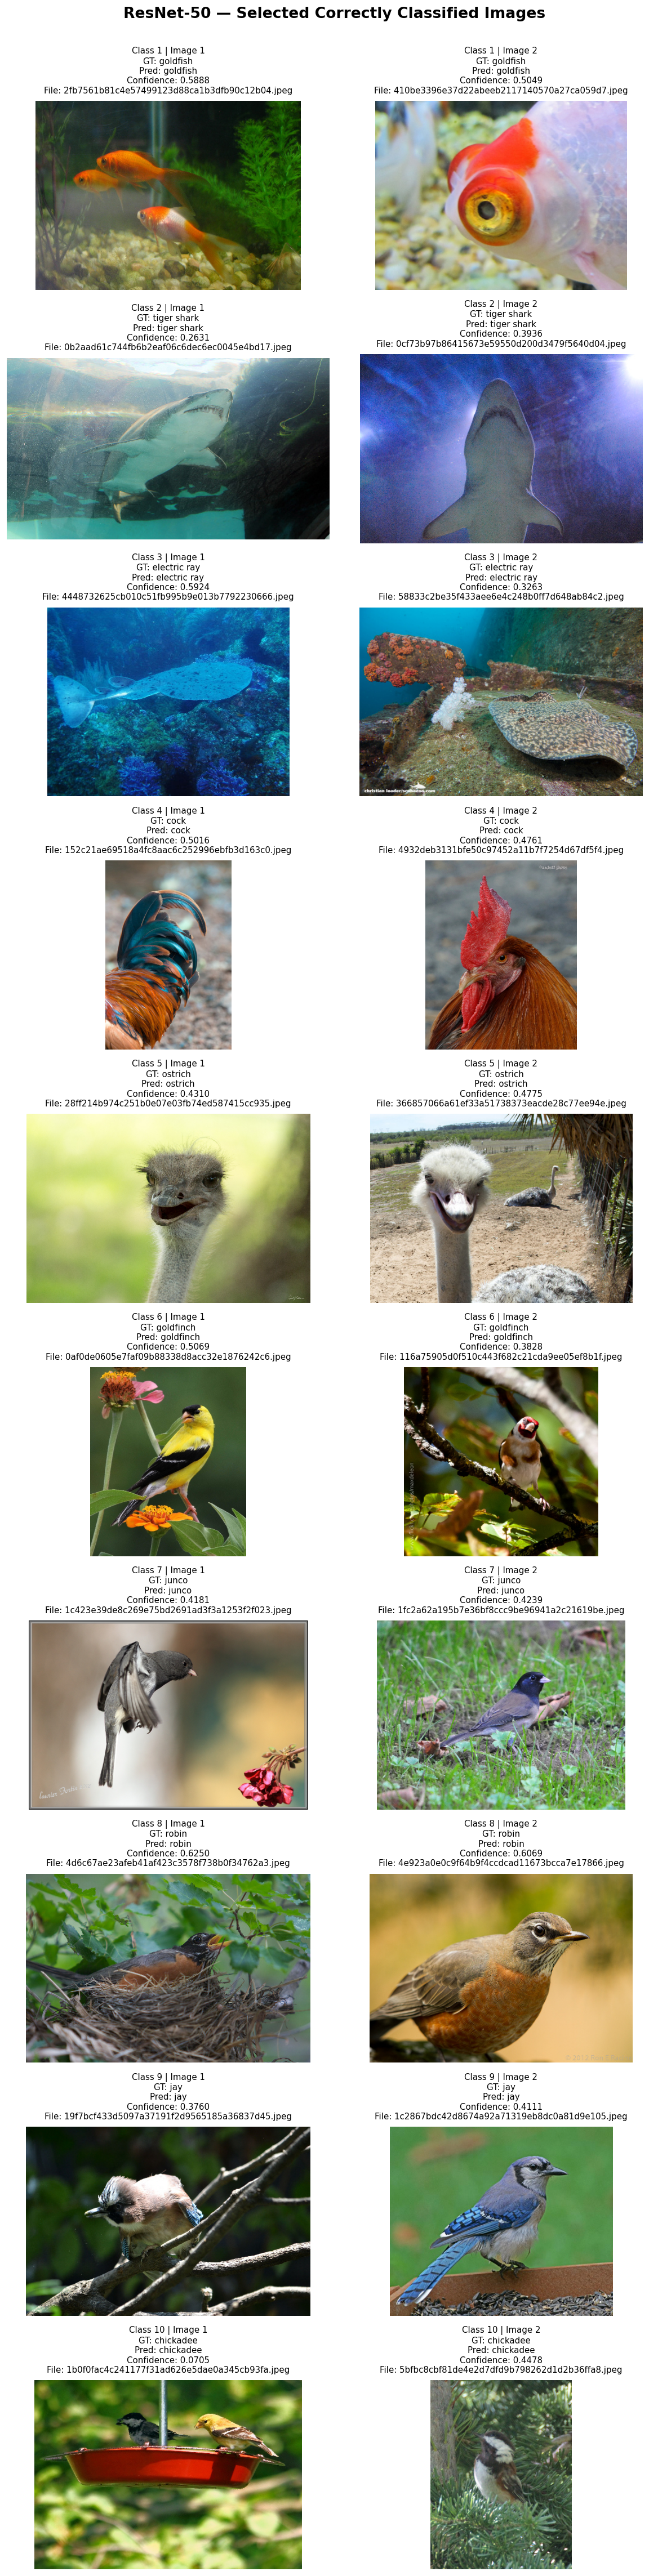

Total selected correct images: 20


In [11]:

# ============================================================
# CELL 7-1 — Visualize selected correctly classified images
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from IPython.display import display

# ==================== Configuration ====================
SHOW_SELECTED_IMAGES = True

# Display settings
FIGURE_WIDTH_PER_IMAGE = 5.0
FIGURE_HEIGHT_PER_CLASS = 3.8
IMAGE_DPI = 120

SHOW_CLASS_NAME = True
SHOW_CONFIDENCE = True
SHOW_ORIGINAL_FILENAME = True

# Save visualization
SAVE_FIGURE = True
FIGURE_PATH = REPORT_ROOT / "resnet50_selected_correct_images.png"

# ==================== Visualization ====================
if SHOW_SELECTED_IMAGES:

    n_classes = len(CLASS_IDS)
    n_images = CORRECT_PER_CLASS

    fig, axes = plt.subplots(
        n_classes,
        n_images,
        figsize=(
            FIGURE_WIDTH_PER_IMAGE * n_images,
            FIGURE_HEIGHT_PER_CLASS * n_classes
        ),
        dpi=IMAGE_DPI,
        squeeze=False
    )

    for class_num, label in enumerate(CLASS_IDS, start=1):

        class_df = correct_df[
            correct_df["class_number"] == class_num
        ].sort_values("image_number")

        for col in range(n_images):

            ax = axes[class_num - 1, col]
            ax.axis("off")

            if col >= len(class_df):
                ax.set_title("No correct image", fontsize=10)
                continue

            row = class_df.iloc[col]

            image_path = Path(row["correct_saved_path"])

            with Image.open(image_path) as im:
                image = np.asarray(im.convert("RGB"))

            ax.imshow(image)

            # Image identification
            title_lines = [
                f"Class {class_num} | Image {int(row['image_number'])}"
            ]

            if SHOW_CLASS_NAME:
                title_lines.append(
                    f"GT: {row['true_name']}"
                )
                title_lines.append(
                    f"Pred: {row['pred_name']}"
                )

            if SHOW_CONFIDENCE:
                title_lines.append(
                    f"Confidence: {row['confidence']:.4f}"
                )

            if SHOW_ORIGINAL_FILENAME:
                title_lines.append(
                    f"File: {row['original_filename']}"
                )

            ax.set_title(
                "\n".join(title_lines),
                fontsize=9,
                pad=8
            )

    plt.suptitle(
        "ResNet-50 — Selected Correctly Classified Images",
        fontsize=16,
        fontweight="bold",
        y=1.002
    )

    plt.tight_layout()

    if SAVE_FIGURE:
        FIGURE_PATH.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        fig.savefig(
            FIGURE_PATH,
            dpi=IMAGE_DPI,
            bbox_inches="tight"
        )

        print("Saved figure:", FIGURE_PATH)

    plt.show()

print("Total selected correct images:", len(correct_df))


In [23]:
# CELL 8 — Original notebook transformations: reusable functions
# RGB float arrays in [0,1]. Boundary pixels use ONLY available 8-neighbors.
def get_neighbor_reference_colors(image):
    if image.ndim!=3 or image.shape[2]!=3: raise ValueError('Expect RGB (H,W,3)')
    h,w,_=image.shape
    padded=np.pad(image,((1,1),(1,1),(0,0)),mode='edge')
    values=[]; valids=[]
    for dy in (-1,0,1):
        for dx in (-1,0,1):
            if dy==0 and dx==0:continue
            values.append(padded[1+dy:1+dy+h,1+dx:1+dx+w,:])
            y=np.arange(h)+dy; x=np.arange(w)+dx
            valids.append(((y[:,None]>=0)&(y[:,None]<h)&(x[None,:]>=0)&(x[None,:]<w)))
    values=np.stack(values);valid=np.stack(valids)
    mean_rgb=np.where(valid[...,None],values,0).sum(axis=0)/valid.sum(axis=0)[...,None]
    median_rgb=np.nanmedian(np.where(valid[...,None],values,np.nan),axis=0)
    dist=np.sum((values-mean_rgb[None,...])**2,axis=-1)
    ix=np.argmin(np.where(valid,dist,np.inf),axis=0)
    nearest=np.take_along_axis(values,ix[None,...,None],axis=0)[0]
    return {'median':median_rgb.astype(np.float32),'mean':mean_rgb.astype(np.float32),
            'nearest_neighbor':nearest.astype(np.float32)}

def add_ratio_gaussian_noise(reference_rgb,variation=10.0,seed=0):
    if variation<0:raise ValueError('variation must be >=0')
    rng=np.random.default_rng(seed)
    base=np.clip(reference_rgb*255,0,255)
    total=base.sum(axis=2,keepdims=True)
    props=np.divide(base,total,out=np.full_like(base,1/3),where=total>0)
    delta=rng.normal(0,variation,size=reference_rgb.shape[:2])
    return np.clip(base+delta[...,None]*props,0,255).astype(np.float32)/255.0

def gray(rgb):return 0.2126*rgb[...,0]+0.7152*rgb[...,1]+0.0722*rgb[...,2]
def convolve3x3(x,kernel):
    padded=np.pad(x,1,mode='edge');out=np.zeros_like(x,dtype=np.float32)
    for i in range(3):
        for j in range(3):out+=kernel[i,j]*padded[i:i+x.shape[0],j:j+x.shape[1]]
    return out

def edge_overlay(rgb,method='sobel',sobel_strength=0.8,laplacian_strength=1.5):
    x=gray(rgb)
    if method=='sobel':
        sx=np.array([[-1,0,1],[-2,0,2],[-1,0,1]],dtype=np.float32)
        edges=np.clip(np.hypot(convolve3x3(x,sx),convolve3x3(x,sx.T))/(4*np.sqrt(2)),0,1)
        strength=sobel_strength
    elif method=='laplacian':
        lk=np.array([[0,1,0],[1,-4,1],[0,1,0]],dtype=np.float32)
        edges=np.clip(np.abs(convolve3x3(x,lk)),0,1)
        strength=laplacian_strength
    else:raise ValueError('Choose sobel or laplacian')
    return np.clip(rgb+edges[...,None]*strength,0,1)

def unsharp(rgb,radius=2.0,amount=1.5):
    base=np.uint8(np.clip(np.round(rgb*255),0,255))
    blurred=np.asarray(Image.fromarray(base).filter(ImageFilter.GaussianBlur(radius=radius)),dtype=np.float32)/255.0
    return np.clip(rgb+amount*(rgb-blurred),0,1)

def read_rgb(p):
    with Image.open(p) as im:return np.asarray(im.convert('RGB'),dtype=np.float32)/255.0

def save_rgb(x,p):
    Path(p).parent.mkdir(parents=True,exist_ok=True)
    Image.fromarray(np.uint8(np.clip(np.round(x*255),0,255))).save(p)


In [24]:
# CELL 9 — ★ Noise settings & generation ★
NOISE_REFERENCE = 'median'       # 'median', 'mean', 'nearest_neighbor'
NOISE_VARIATION = 50.0          # std dev at 8-bit pixel scale; original notebook: 40.0
NOISE_SEED = SEED
MAX_SIDE = None                 # None: preserve full original resolution; e.g. 768 speeds up

assert NOISE_REFERENCE in ('median','mean','nearest_neighbor')

def load_for_processing(path):
    if MAX_SIDE is None:return read_rgb(path)
    with Image.open(path) as im:
        im=im.convert('RGB');im.thumbnail((MAX_SIDE,MAX_SIDE),Image.Resampling.LANCZOS)
        return np.asarray(im,dtype=np.float32)/255.0

for r in tqdm(correct_rows,desc='Noise'):
    label=int(r['true_label']);cn=int(r['class_number']);n=int(r['image_number'])
    image=load_for_processing(r['correct_saved_path'])
    p=OUTPUT_ROOT/str(label)/f'class_{cn}_{n}_noise.png'
    ref=get_neighbor_reference_colors(image)[NOISE_REFERENCE]
    save_rgb(add_ratio_gaussian_noise(ref,variation=NOISE_VARIATION,seed=NOISE_SEED+cn*100+n),p)
print('Noise: done')


Noise:   0%|          | 0/20 [00:00<?, ?it/s]

Noise: done


In [25]:
# CELL 10 — ★ Overlay settings & generation ★
OVERLAY_METHOD = 'laplacian'       # 'sobel' or 'laplacian'
SOBEL_STRENGTH = 0.8
LAPLACIAN_STRENGTH = 2.2

for r in tqdm(correct_rows,desc='Overlay'):
    label=int(r['true_label']);cn=int(r['class_number']);n=int(r['image_number'])
    image=load_for_processing(r['correct_saved_path'])
    p=OUTPUT_ROOT/str(label)/f'class_{cn}_{n}_overlay.png'
    save_rgb(edge_overlay(image,method=OVERLAY_METHOD,
                          sobel_strength=SOBEL_STRENGTH,
                          laplacian_strength=LAPLACIAN_STRENGTH),p)
print('Overlay: done')


Overlay:   0%|          | 0/20 [00:00<?, ?it/s]

Overlay: done


In [26]:
# CELL 11 — ★ Unsharp settings & generation ★
UNSHARP_RADIUS = 3.0
UNSHARP_AMOUNT = 2

for r in tqdm(correct_rows,desc='Unsharp'):
    label=int(r['true_label']);cn=int(r['class_number']);n=int(r['image_number'])
    image=load_for_processing(r['correct_saved_path'])
    p=OUTPUT_ROOT/str(label)/f'class_{cn}_{n}_unsharp.png'
    save_rgb(unsharp(image,radius=UNSHARP_RADIUS,amount=UNSHARP_AMOUNT),p)
print('Unsharp: done')


Unsharp:   0%|          | 0/20 [00:00<?, ?it/s]

Unsharp: done


In [31]:
# CELL 11-1 — ★ Smoothing filters: Gaussian / Median / Mean ★
# These are spatial filters applied directly to the ORIGINAL selected images,
# not the median/mean neighbor reference used in CELL 9 for additive noise.
# Run after CELL 9 (load_for_processing, save_rgb) and CELL 7 (correct_rows).

# ==================== Configuration ====================
FILTER_METHODS = ['gaussian', 'median', 'mean']  # choose one or more, e.g. ['gaussian']
GAUSSIAN_RADIUS = 3.0       # PIL GaussianBlur radius (pixels); 0 = no blur
MEDIAN_KERNEL_SIZE = 5     # odd integer >= 3 (3, 5, 7, ...)
MEAN_KERNEL_SIZE = 5       # odd integer >= 3 (3, 5, 7, ...)

# 'class_1_1_gaussian.png', 'class_1_1_median.png', 'class_1_1_mean.png'
VALID_FILTERS = {'gaussian', 'median', 'mean'}
FILTER_METHODS = list(dict.fromkeys(FILTER_METHODS))
if not FILTER_METHODS or any(m not in VALID_FILTERS for m in FILTER_METHODS):
    raise ValueError(f'FILTER_METHODS must contain names from {sorted(VALID_FILTERS)}')
if GAUSSIAN_RADIUS < 0:
    raise ValueError('GAUSSIAN_RADIUS must be >= 0')
for name, size in [('MEDIAN_KERNEL_SIZE', MEDIAN_KERNEL_SIZE),
                   ('MEAN_KERNEL_SIZE', MEAN_KERNEL_SIZE)]:
    if not isinstance(size, int) or size < 3 or size % 2 == 0:
        raise ValueError(f'{name} must be odd integer >= 3')

# Save float RGB arrays using existing CELL 8 utilities
for r in tqdm(correct_rows, desc='Smoothing filters'):
    label = int(r['true_label'])
    cn = int(r['class_number'])
    idx = int(r['image_number'])
    rgb = load_for_processing(r['correct_saved_path'])
    pil_img = Image.fromarray(np.uint8(np.clip(np.round(rgb * 255), 0, 255)))
    folder = OUTPUT_ROOT / str(label)

    for method in FILTER_METHODS:
        if method == 'gaussian':
            result = pil_img.filter(ImageFilter.GaussianBlur(radius=GAUSSIAN_RADIUS))
        elif method == 'median':
            result = pil_img.filter(ImageFilter.MedianFilter(size=MEDIAN_KERNEL_SIZE))
        elif method == 'mean':
            result = pil_img.filter(ImageFilter.BoxBlur(radius=(MEAN_KERNEL_SIZE - 1) / 2))
            # BoxBlur radius=1 averages a 3x3 box; radius=2 averages a 5x5 box.
        result.save(folder / f'class_{cn}_{idx}_{method}.png')

print(f'Filters generated: {FILTER_METHODS}')
print(f'Added images: {len(correct_rows) * len(FILTER_METHODS)}')

Smoothing filters:   0%|          | 0/20 [00:00<?, ?it/s]

Filters generated: ['gaussian', 'median', 'mean']
Added images: 60


In [28]:
# CELL 12 — Save originals, result manifest, and image count validation
# Producing originals here ensures ori matches the input resolution used for transforms.
manifest=[]
for r in correct_rows:
    label=int(r['true_label']);cn=int(r['class_number']);n=int(r['image_number'])
    prefix=f'class_{cn}_{n}'
    folder=OUTPUT_ROOT/str(label)
    ori=folder/f'{prefix}_ori.png'
    save_rgb(load_for_processing(r['correct_saved_path']),ori)
    for variant in ('ori','noise','overlay','unsharp', *FILTER_METHODS):
        fp=folder/f'{prefix}_{variant}.png'
        manifest.append({'class_number':cn,'imagenet_label':label,'class_name':class_names[label],
                         'image_number':n,'variant':variant,'file_path':str(fp),
                         'exists':fp.is_file(),'source_filename':r['original_filename'],
                         'resnet50_confidence':r['confidence']})
manifest_df=pd.DataFrame(manifest)
manifest_df.to_csv(REPORT_ROOT/'output_manifest.csv',index=False)
print('Current run manifest files:',len(manifest_df),' / present:',manifest_df['exists'].sum())
print(manifest_df.groupby(['imagenet_label','variant']).size().unstack(fill_value=0).to_string())
assert manifest_df['exists'].all(), 'Run Cells 9, 10, 11, and 11-1 first.'


Current run manifest files: 140  / present: 140
variant         gaussian  mean  median  noise  ori  overlay  unsharp
imagenet_label                                                      
1                      2     2       2      2    2        2        2
3                      2     2       2      2    2        2        2
5                      2     2       2      2    2        2        2
7                      2     2       2      2    2        2        2
9                      2     2       2      2    2        2        2
11                     2     2       2      2    2        2        2
13                     2     2       2      2    2        2        2
15                     2     2       2      2    2        2        2
17                     2     2       2      2    2        2        2
19                     2     2       2      2    2        2        2


In [ ]:
# CELL 13 — Preview one selected image (2 × 2)
PREVIEW_CLASS_NUMBER = 1   # local class number 1..10
PREVIEW_IMAGE_NUMBER = 1

label=CLASS_IDS[PREVIEW_CLASS_NUMBER-1]
folder=OUTPUT_ROOT/str(label)
fig,axs=plt.subplots(2,2,figsize=(10,9))
for ax,variant in zip(axs.flat,('ori','noise','overlay','unsharp')):
    fp=folder/f'class_{PREVIEW_CLASS_NUMBER}_{PREVIEW_IMAGE_NUMBER}_{variant}.png'
    if fp.exists():
        with Image.open(fp) as im:ax.imshow(im)
        ax.set_title(variant)
    else:ax.set_title(f'Missing: {variant}')
    ax.axis('off')
plt.tight_layout();plt.show()


In [ ]:
# CELL 14 — Optional: zip processed results to Drive
MAKE_ZIP = False
if MAKE_ZIP:
    archive_path=shutil.make_archive(str(WORK_ROOT/'processed_images'),'zip',root_dir=WORK_ROOT,base_dir='processed')
    print('ZIP:',archive_path)
